# 04 · Aprendizaje no supervisado: segmentos de comportamiento
**Proyecto final · Análisis de datos, BI y aprendizaje computacional**

## Para qué sirve esta etapa
El modelo supervisado dice **cuánto riesgo** tiene cada ciclo, pero no explica **qué tipo de suscriptor** es. Aquí se agrupa a los suscriptores **solo por cómo se comportan** (sin mirar si renovaron ni su tipo de entrada) y después se revisa si esos grupos tienen riesgos distintos. Así los segmentos son una herramienta para **entender y comunicar**, y se validan contra el churn al final.

## Técnicas 
Transformación y estandarización → **PCA** (reducir variables correlacionadas) → **K-Means** (elección de k por codo y silueta, estabilidad entre semillas) → **t-SNE** (visualizar la estructura en 2 dimensiones).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, adjusted_rand_score

RAIZ = Path("..").resolve(); sys.path.append(str(RAIZ))
from src import features
PROC = RAIZ / "data" / "processed"; FIG = RAIZ / "resultados" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
AZUL, ROJO, GRIS = "#2F6DB5", "#B3261E", "#8A94A0"
PALETA = ["#2F6DB5", "#E08A1E", "#4C9F70", "#B3261E", "#7B5EA7", "#8A94A0"]
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200, "display.max_columns", 60)

snap = pd.read_csv(PROC / "fact_snapshot_mensual.csv")
ciclos = pd.read_csv(PROC / "fact_ciclo.csv", dtype={"productoid": str, "ordenid": str},
                     parse_dates=["ciclo_inicio", "ciclo_fin", "fecha_pago", "inicio_renovacion", "fecha_pago_renovacion"])
base = features.base_horizonte(snap, ciclos, 60)
base = base[base["sin_foto_previa"] == 0].reset_index(drop=True)     # solo ciclos con comportamiento observado
print(f"Ciclos con comportamiento observado a 60 días del vencimiento: {len(base):,}")

Ciclos con comportamiento observado a 60 días del vencimiento: 40,789


## 1. Variables y preparación
Solo **comportamiento y antigüedad**; no se usan el tipo de entrada ni el churn. Los conteos tienen muchos ceros y colas largas, por eso se aplica `log(1+x)` antes de estandarizar (K-Means usa distancias y se dejaría dominar por las variables más grandes).

In [2]:
COLS = ["nav_media", "nav_ult3", "meses_con_uso", "variedad_uso", "apertura_boletin_prom", "descarga_mformatos_prom",
        "peticiones_calculadoras_prom", "peticiones_guias_prom", "peticiones_r_actualizacion_prom", "preguntas_ia_prom",
        "solicitudes_soporte_prom", "antiguedad_meses", "ciclos_previos", "L_nav_6m", "L_nav_cambio", "dias_inactividad_ult"]
X = base[COLS].copy()
for c in COLS:
    X[c] = np.sign(X[c]) * np.log1p(X[c].abs())         # igual a log(1+x) para valores >= 0
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))
pca = PCA(n_components=0.85, random_state=0).fit(Z); P = pca.transform(Z)
print(f"{Z.shape[1]} variables → {P.shape[1]} componentes que explican el {pca.explained_variance_ratio_.sum():.0%} de la varianza")
cargas = pd.DataFrame(pca.components_[:3].T, index=COLS, columns=["CP1", "CP2", "CP3"]).round(2)
cargas.assign(abs1=cargas["CP1"].abs()).sort_values("abs1", ascending=False).drop(columns="abs1").head(8)

16 variables → 7 componentes que explican el 88% de la varianza


,CP1,CP2,CP3
nav_media,0.36,-0.06,-0.04
L_nav_6m,0.35,-0.13,0.21
descarga_mformatos_prom,0.34,-0.08,0.03
meses_con_uso,0.33,0.04,0.01
nav_ult3,0.32,-0.15,0.28
variedad_uso,0.31,0.04,-0.08
peticiones_r_actualizacion_prom,0.31,0.01,-0.29
dias_inactividad_ult,-0.28,0.07,-0.18


## 2. Elección de k: codo y silueta

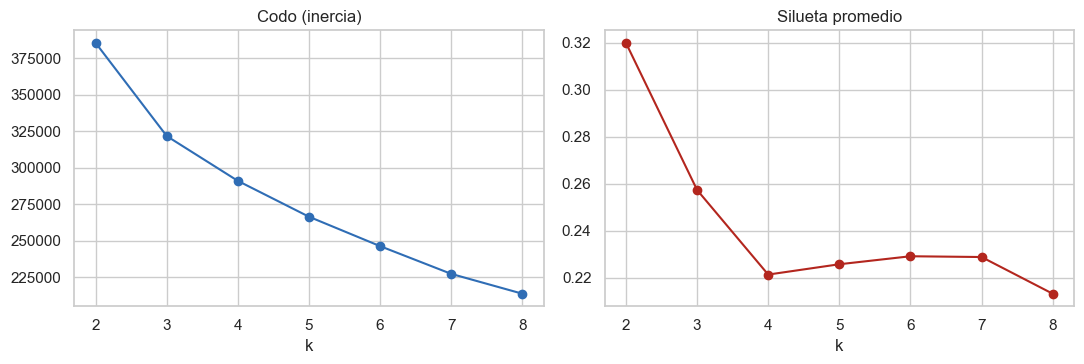

,inercia,silueta
2,385395.938611,0.320
3,321629.927380,0.257
4,290952.779047,0.221
5,266413.532618,0.226
6,246284.570269,0.229
7,227299.302253,0.229
8,213718.965320,0.213


In [3]:
rng = np.random.RandomState(0); muestra = rng.choice(len(P), 6000, replace=False)
ks = range(2, 9); inercia, silueta = [], []
for k in ks:
    km = KMeans(k, n_init=5, random_state=0).fit(P)
    inercia.append(km.inertia_); silueta.append(silhouette_score(P[muestra], km.labels_[muestra]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(list(ks), inercia, marker="o", color=AZUL); ax[0].set_title("Codo (inercia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), silueta, marker="o", color=ROJO); ax[1].set_title("Silueta promedio"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig(FIG / "cluster_k.png", dpi=130); plt.show()
pd.DataFrame({"inercia": inercia, "silueta": np.round(silueta, 3)}, index=list(ks))

**Decisión:** la silueta es baja en todos los k (0,21–0,32): **no hay grupos naturales bien separados**, sino un continuo de comportamiento. Esto es normal en suscriptores. Se usa **k = 4**: es donde el codo se aplana y es el mínimo que separa perfiles con significado de negocio. Los segmentos sirven para describir, no son "especies" distintas. Se comprueba que sean estables.

In [4]:
K = 4
km = KMeans(K, n_init=20, random_state=0).fit(P)
base["segmento"] = km.labels_
# estabilidad: ¿se obtienen los mismos grupos con otras semillas y con otra mitad de los datos?
aris = [adjusted_rand_score(km.labels_, KMeans(K, n_init=5, random_state=s).fit(P).labels_) for s in range(1, 6)]
print(f"Estabilidad entre semillas (ARI, 1 = idéntico): promedio {np.mean(aris):.2f}, mínimo {np.min(aris):.2f}")
print("Tamaño de los segmentos:", base["segmento"].value_counts(normalize=True).sort_index().round(3).to_dict())

Estabilidad entre semillas (ARI, 1 = idéntico): promedio 0.99, mínimo 0.98
Tamaño de los segmentos: {0: 0.298, 1: 0.111, 2: 0.359, 3: 0.232}


## 3. Perfil de cada segmento
Medianas de las variables originales (las medias se distorsionan por los valores extremos).

In [5]:
perfil = base.groupby("segmento")[COLS].median().round(2)
perfil["tamaño"] = base["segmento"].value_counts().sort_index()
perfil.T

segmento,0,1,2,3
nav_media,0.60,2.91,0.0,1.20
nav_ult3,0.33,2.67,0.0,1.67
meses_con_uso,4.00,9.00,0.0,6.00
variedad_uso,4.00,8.00,1.0,5.00
apertura_boletin_prom,2.00,4.45,1.5,2.60
descarga_mformatos_prom,0.45,1.90,0.0,1.00
peticiones_calculadoras_prom,0.00,0.09,0.0,0.00
peticiones_guias_prom,0.00,0.27,0.0,0.00
peticiones_r_actualizacion_prom,0.09,1.00,0.0,0.09
preguntas_ia_prom,0.00,0.00,0.0,0.00


## 4. Visualización: PCA y t-SNE

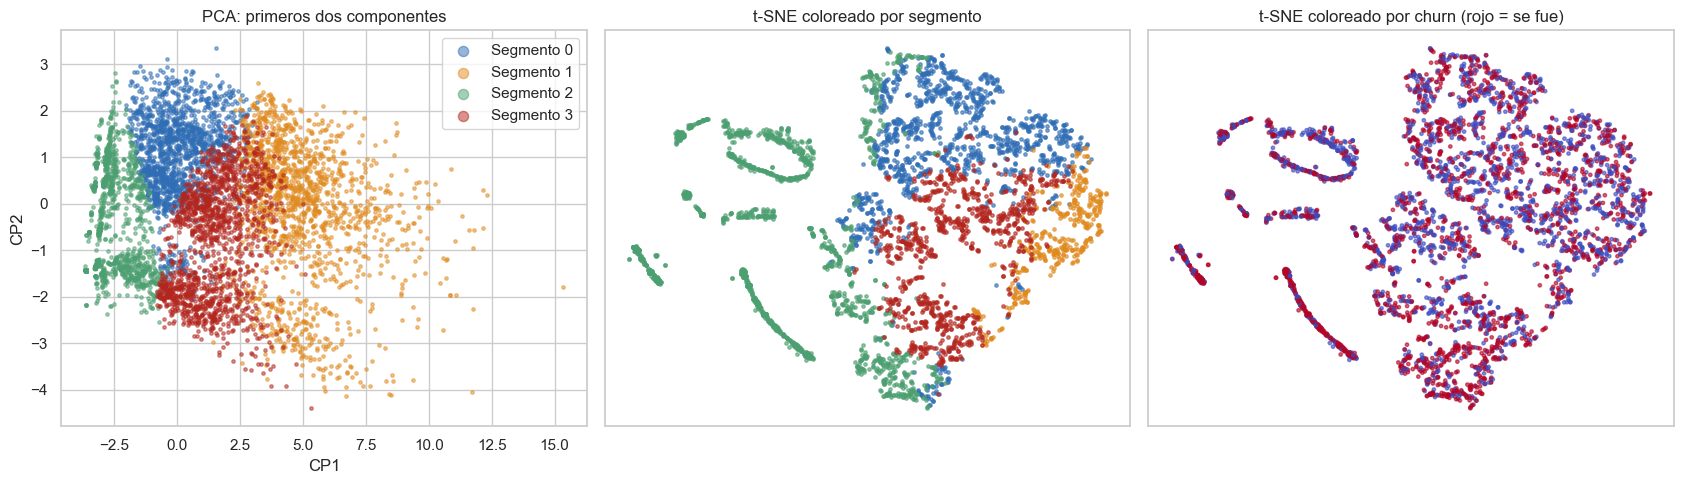

In [6]:
muestra_t = rng.choice(len(P), 4000, replace=False)
tsne = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=0).fit_transform(P[muestra_t])
seg_t = base["segmento"].values[muestra_t]; churn_t = base["churn90"].values[muestra_t]
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for s_ in range(K):
    m_ = base["segmento"].values == s_
    ax[0].scatter(P[m_, 0][:1500], P[m_, 1][:1500], s=6, alpha=.5, color=PALETA[s_], label=f"Segmento {s_}")
ax[0].set_title("PCA: primeros dos componentes"); ax[0].set_xlabel("CP1"); ax[0].set_ylabel("CP2"); ax[0].legend(markerscale=3)
for s_ in range(K):
    ax[1].scatter(tsne[seg_t == s_, 0], tsne[seg_t == s_, 1], s=6, alpha=.6, color=PALETA[s_])
ax[1].set_title("t-SNE coloreado por segmento")
sc = ax[2].scatter(tsne[:, 0], tsne[:, 1], c=churn_t, s=6, alpha=.6, cmap="coolwarm"); ax[2].set_title("t-SNE coloreado por churn (rojo = se fue)")
for a in ax[1:]: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "cluster_pca_tsne.png", dpi=130); plt.show()

## 5. ¿Los segmentos tienen riesgos distintos? (validación contra el churn)
El churn **no** se usó para formar los segmentos; aquí se comprueba si, de todos modos, separan riesgos.

In [7]:
resumen = base.groupby("segmento").agg(ciclos=("churn90", "size"), churn=("churn90", "mean"),
    pct_nueva=("tipo_entrada", lambda x: (x == "NUEVA").mean()), pct_reactivacion=("tipo_entrada", lambda x: (x == "REACTIVACION").mean()),
    pct_renovacion=("tipo_entrada", lambda x: (x == "RENOVACION").mean()), pct_upgrade=("tipo_entrada", lambda x: (x == "UPGRADE").mean()))
resumen["% de los que se van"] = base.groupby("segmento")["churn90"].sum() / base["churn90"].sum()
display(resumen.round(3))

# dentro de cada tipo de entrada: ¿el segmento sigue separando riesgo? (descarta que solo sea el tipo de entrada)
dentro = base[base["tipo_entrada"].isin(["NUEVA", "REACTIVACION", "RENOVACION"])].pivot_table(
    index="segmento", columns="tipo_entrada", values="churn90", aggfunc="mean").round(3)
print("Churn por segmento dentro de cada tipo de entrada:"); dentro

,ciclos,churn,pct_nueva,pct_reactivacion,pct_renovacion,pct_upgrade,% de los que se van
segmento,,,,,,,
0,12143,0.518,0.048,0.341,0.514,0.095,0.286
1,4536,0.477,0.158,0.269,0.493,0.076,0.098
2,14631,0.600,0.411,0.254,0.231,0.102,0.398
3,9479,0.507,0.327,0.226,0.321,0.124,0.218


Churn por segmento dentro de cada tipo de entrada:


tipo_entrada,NUEVA,REACTIVACION,RENOVACION
segmento,,,
0,0.724,0.559,0.484
1,0.596,0.482,0.457
2,0.740,0.552,0.461
3,0.630,0.510,0.428


Chi² segmento vs. churn: 348, p = 3.6e-75, V de Cramér = 0.092


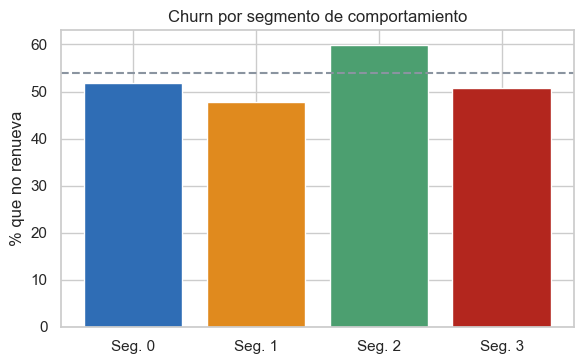

In [8]:
from scipy import stats
ct = pd.crosstab(base["segmento"], base["churn90"]); chi, p, _, _ = stats.chi2_contingency(ct)
print(f"Chi² segmento vs. churn: {chi:.0f}, p = {p:.1e}, V de Cramér = {np.sqrt(chi / (ct.values.sum() * (min(ct.shape) - 1))):.3f}")
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar([f"Seg. {i}" for i in resumen.index], resumen["churn"] * 100, color=PALETA[:K])
ax.axhline(base["churn90"].mean() * 100, color=GRIS, ls="--"); ax.set_ylabel("% que no renueva"); ax.set_title("Churn por segmento de comportamiento")
plt.tight_layout(); plt.savefig(FIG / "cluster_churn.png", dpi=130); plt.show()

## 6. Rediseño: ¿se pueden separar mejor los grupos? (depuración de variables y otros algoritmos)
La silueta de 0,22 es baja. Antes de aceptarla se revisó si el problema eran **variables redundantes** (muchas miden lo mismo), la **dimensión** del espacio o el **algoritmo**. La silueta cae de forma natural cuando hay muchas variables correlacionadas con muchos ceros, así que se probaron tres rediseños y se compararon con tres medidas: silueta (más alto es mejor), índice de Davies-Bouldin (más bajo es mejor) y Calinski-Harabasz (más alto es mejor).

### 6.1 Correlación entre las variables de uso

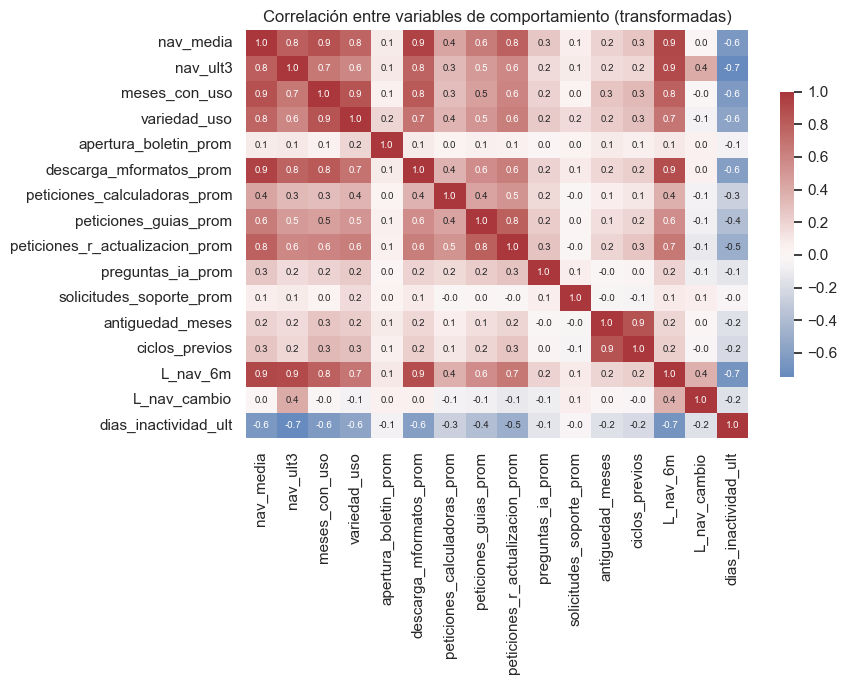

Pares más correlacionados (|r|):


|r|
nav_media               descarga_mformatos_prom  0.94
                        L_nav_6m                 0.92
nav_ult3                L_nav_6m                 0.90
descarga_mformatos_prom L_nav_6m                 0.88
nav_media               meses_con_uso            0.87
antiguedad_meses        ciclos_previos           0.86
meses_con_uso           variedad_uso             0.86
                        descarga_mformatos_prom  0.82

In [9]:
corr = pd.DataFrame(Z, columns=COLS).corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Correlación entre variables de comportamiento (transformadas)")
plt.tight_layout(); plt.savefig(FIG / "cluster_correlacion.png", dpi=130); plt.show()
pares = corr.abs().where(np.triu(np.ones(corr.shape), 1) == 1).stack().sort_values(ascending=False)
print("Pares más correlacionados (|r|):"); display(pares.head(8).round(2).rename("|r|").to_frame())

Hay grupos de variables casi duplicadas (promedio de navegación, navegación de los últimos 6 meses y descargas de formatos superan 0,9). Cuando esas variables pesan varias veces en la distancia, el clustering se deja llevar por una sola dimensión: la intensidad de uso.

### 6.2 Comparación de diseños y algoritmos

In [10]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

def preparar(cols):
    Xc = base[cols].copy()
    for c in cols: Xc[c] = np.sign(Xc[c]) * np.log1p(Xc[c].abs())
    return StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(Xc))

def podar(cols, umbral):
    c = pd.DataFrame(preparar(cols), columns=cols).corr().abs(); fuera = set()
    for i, a in enumerate(cols):
        if a in fuera: continue
        fuera |= {b for b in cols[i + 1:] if b not in fuera and c.loc[a, b] > umbral}
    return [x for x in cols if x not in fuera]

rng_c = np.random.RandomState(0); idx = rng_c.choice(len(base), 6000, replace=False)
def medir(nombre, Zs, etiquetas, k):
    return {"diseño": nombre, "k": k, "silueta": silhouette_score(Zs[idx], etiquetas[idx]),
            "Davies-Bouldin": davies_bouldin_score(Zs[idx], etiquetas[idx]), "Calinski-Harabasz": calinski_harabasz_score(Zs[idx], etiquetas[idx])}

MINIMO = ["nav_media", "meses_con_uso", "variedad_uso", "dias_inactividad_ult", "L_nav_cambio"]   # intensidad, continuidad, variedad, inactividad, tendencia
P7 = podar(COLS, 0.7); P5 = podar(COLS, 0.5)
filas = []
for k in (3, 4, 5):
    filas.append(medir("A · 16 variables + PCA (versión inicial)", P, KMeans(k, n_init=5, random_state=0).fit_predict(P), k))
Z7, Z5, Zm = preparar(P7), preparar(P5), preparar(MINIMO)
filas.append(medir(f"B · podadas |r|>0,7 ({len(P7)} variables)", Z7, KMeans(4, n_init=5, random_state=0).fit_predict(Z7), 4))
filas.append(medir(f"C · podadas |r|>0,5 ({len(P5)} variables)", Z5, KMeans(4, n_init=5, random_state=0).fit_predict(Z5), 4))
for k in (3, 4, 5):
    filas.append(medir("D · conjunto compacto (5 variables)", Zm, KMeans(k, n_init=5, random_state=0).fit_predict(Zm), k))
filas.append(medir("D · compacto con mezcla gaussiana", Zm, GaussianMixture(4, random_state=0, n_init=2).fit_predict(Zm), 4))
sub = rng_c.choice(len(base), 5000, replace=False); lab_w = np.full(len(base), -1); lab_w[sub] = AgglomerativeClustering(4, linkage="ward").fit_predict(Zm[sub])
filas.append({"diseño": "D · compacto con jerárquico (Ward, muestra)", "k": 4, "silueta": silhouette_score(Zm[sub], lab_w[sub]),
              "Davies-Bouldin": davies_bouldin_score(Zm[sub], lab_w[sub]), "Calinski-Harabasz": calinski_harabasz_score(Zm[sub], lab_w[sub])})
comparacion = pd.DataFrame(filas).round(3); print("Variables quitadas al podar a 0,7:", sorted(set(COLS) - set(P7)))
comparacion

Variables quitadas al podar a 0,7: ['L_nav_6m', 'ciclos_previos', 'descarga_mformatos_prom', 'meses_con_uso', 'nav_ult3', 'peticiones_r_actualizacion_prom', 'variedad_uso']


,diseño,k,silueta,Davies-Bouldin,Calinski-Harabasz
0,A · 16 variables + PCA (versión inicial),3,0.257,1.445,2376.426
1,A · 16 variables + PCA (versión inicial),4,0.221,1.620,1949.770
2,A · 16 variables + PCA (versión inicial),5,0.226,1.490,1729.729
3,"B · podadas |r|>0,7 (9 variables)",4,0.208,1.687,1003.333
4,"C · podadas |r|>0,5 (7 variables)",4,0.195,1.608,970.283
5,D · conjunto compacto (5 variables),3,0.391,1.138,4429.897
6,D · conjunto compacto (5 variables),4,0.391,0.977,4754.434
7,D · conjunto compacto (5 variables),5,0.394,1.044,4535.400
8,D · compacto con mezcla gaussiana,4,0.367,1.033,4329.491
9,"D · compacto con jerárquico (Ward, muestra)",4,0.364,1.053,3566.195


**Lectura.** Quitar variables correlacionadas sin más **no** mejora la separación (silueta 0,18 a 0,22). Lo que sí la mejora es cambiar el diseño: un conjunto compacto de **cinco variables, una por cada dimensión del comportamiento** (intensidad, continuidad, variedad, tiempo sin ingresar y tendencia), sube la silueta a **0,39** y baja el Davies-Bouldin a 0,98. La mezcla gaussiana y el jerárquico (Ward) sobre las mismas cinco variables dan 0,36 y 0,37, casi igual que K-Means: el resultado depende de **qué variables** se usan y no del algoritmo, y ninguno llega a la zona de grupos claramente separados (silueta > 0,5), porque el comportamiento es un continuo.

### 6.3 Segmentación final (conjunto compacto, k = 4)

Estabilidad entre semillas (ARI): promedio 0.99 · silueta 0.39


,nav_media,meses_con_uso,variedad_uso,dias_inactividad_ult,L_nav_cambio,antiguedad_meses,% de los ciclos,churn,% de los que se van
seg2,,,,,,,,,
0,0.00,0.0,1.0,295.0,0.00,26.0,0.251,0.563,0.261
1,1.60,7.0,7.0,19.0,-1.17,38.0,0.189,0.530,0.185
2,0.40,3.0,3.0,254.0,0.17,35.0,0.347,0.566,0.363
3,1.45,7.0,5.0,15.0,1.17,38.0,0.214,0.481,0.190


Churn por segmento dentro del tipo de entrada:


tipo_entrada,NUEVA,RENOVACION
seg2,,
0,0.723,0.446
1,0.678,0.474
2,0.730,0.479
3,0.594,0.447


V de Cramér segmento compacto vs. churn: 0.067 (versión inicial: 0.092)


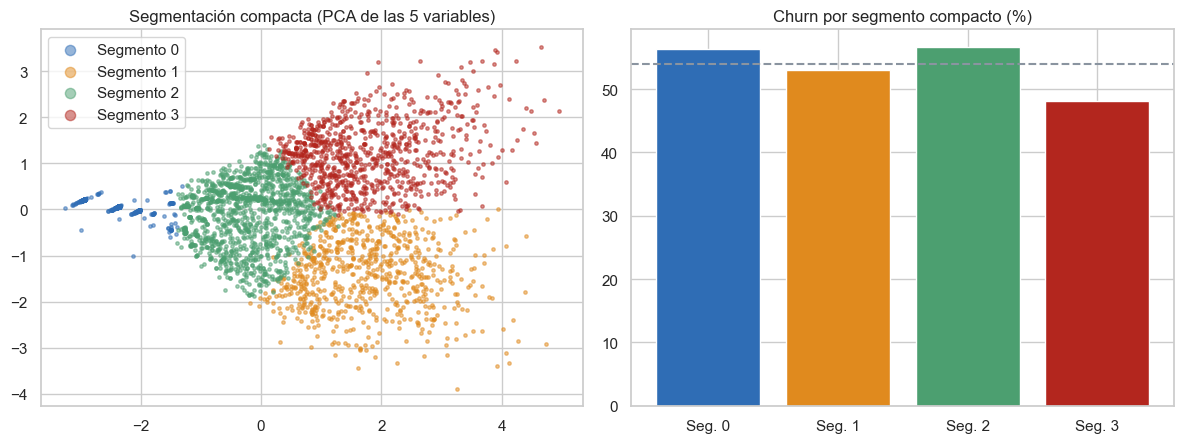

In [11]:
km2 = KMeans(4, n_init=20, random_state=0).fit(Zm); base["seg2"] = km2.labels_
aris2 = [adjusted_rand_score(km2.labels_, KMeans(4, n_init=5, random_state=s).fit_predict(Zm)) for s in range(1, 6)]
print(f"Estabilidad entre semillas (ARI): promedio {np.mean(aris2):.2f} · silueta {silhouette_score(Zm[idx], km2.labels_[idx]):.2f}")
g2 = base.groupby("seg2")
perfil2 = g2[MINIMO + ["antiguedad_meses"]].median().round(2)
perfil2["% de los ciclos"] = (g2.size() / len(base)).round(3); perfil2["churn"] = g2["churn90"].mean().round(3)
perfil2["% de los que se van"] = (g2["churn90"].sum() / base["churn90"].sum()).round(3)
display(perfil2)
dent = base[base["tipo_entrada"].isin(["NUEVA", "RENOVACION"])].pivot_table(index="seg2", columns="tipo_entrada", values="churn90", aggfunc="mean").round(3)
print("Churn por segmento dentro del tipo de entrada:"); display(dent)
ct2 = pd.crosstab(base["seg2"], base["churn90"]); chi2v = stats.chi2_contingency(ct2)[0]
print(f"V de Cramér segmento compacto vs. churn: {np.sqrt(chi2v / ct2.values.sum()):.3f} (versión inicial: {np.sqrt(chi / (ct.values.sum() * (min(ct.shape) - 1))):.3f})")
pc = PCA(2, random_state=0).fit_transform(Zm); m_ = rng_c.choice(len(Zm), 4000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for s_ in range(4): ax[0].scatter(pc[m_][base["seg2"].values[m_] == s_, 0], pc[m_][base["seg2"].values[m_] == s_, 1], s=6, alpha=.5, color=PALETA[s_], label=f"Segmento {s_}")
ax[0].legend(markerscale=3); ax[0].set_title("Segmentación compacta (PCA de las 5 variables)")
ax[1].bar([f"Seg. {i}" for i in perfil2.index], perfil2["churn"] * 100, color=PALETA[:4]); ax[1].axhline(base["churn90"].mean() * 100, color=GRIS, ls="--"); ax[1].set_title("Churn por segmento compacto (%)")
plt.tight_layout(); plt.savefig(FIG / "cluster_compacto.png", dpi=130); plt.show()

## 7. Conclusiones de la etapa

**Resultado en una frase:** el comportamiento de uso forma un continuo, no grupos naturales. Con 16 variables la silueta es 0,22 (separación muy pobre); depurando el diseño a cinco variables sube a **0,39** (estructura débil pero real) y no pasa de ahí con otros algoritmos.

**Qué se intentó (sección 6)**
- Revisar la correlación entre variables: hay pares con |r| > 0,9 (navegación media, navegación de 6 meses, descargas de formatos).
- Podar variables correlacionadas (9 y 7 variables restantes): **no** mejora (silueta 0,20 y 0,21).
- Conjunto compacto de cinco variables, una por dimensión (intensidad, continuidad, variedad, tiempo sin ingresar, tendencia): silueta 0,39 y Davies-Bouldin 0,98 contra 1,62.
- Otros algoritmos sobre ese conjunto: mezcla gaussiana 0,37 y jerárquico 0,36. El límite no es el algoritmo.

**Los cuatro segmentos finales (conjunto compacto, estables con ARI 0,99)**

| Segmento | % de ciclos | Perfil | Churn |
|---|---|---|---|
| Sin uso | 25 % | Casi nunca navegan, unos 295 días sin ingresar | 56 % |
| Uso esporádico y apagado | 35 % | Pocos meses con uso, 254 días sin ingresar | **57 %** |
| Activos que bajan | 19 % | 1,6 días de navegación al mes, 7 meses con uso, uso en caída | 53 % |
| Activos que suben | 21 % | 1,5 días al mes, 7 meses con uso, uso en alza | **48 %** |

**Qué se aprende**
- **La tendencia importa:** entre quienes entran como nuevos, los activos que suben se van 59 % y los que no usan o usan poco 72 % a 73 %, una diferencia de 13 puntos. Entre renovaciones la diferencia desaparece (45 % a 48 %).
- **La separación de riesgo es modesta** (V de Cramér 0,067 en el diseño compacto, 0,092 en el inicial): el diseño compacto separa mejor los grupos pero reparte menos el riesgo. Ningún segmento está a salvo (el mejor tiene 48 % de churn).
- Los segmentos sirven para **entender y comunicar** (a quién activar, a quién reenganchar), no para predecir; para eso está el modelo supervisado.

**Versión inicial de 16 variables (secciones 1 a 5):** conserva un reparto de riesgo algo mayor (48 % a 60 %; los sin uso concentran 40 % de las salidas siendo el 36 % de los ciclos) y se deja como referencia del primer intento.

**Uso en el negocio**
- *Sin uso, nuevos:* activación temprana (recordatorio de primeros pasos, contenido de bienvenida) antes del corte de 60 días.
- *Activos que bajan:* mensaje de reenganche con contenido relevante cuando la tendencia cae, antes de que el uso se apague.
- *Activos que suben:* riesgo menor, candidatos a renovación anticipada o planes largos.

**Limitaciones:** variables de uso con muchos ceros (por eso el logaritmo), silueta inferior a 0,5 y solo se agrupó a quienes tienen comportamiento observado (41 % de los ciclos no tiene fotos mensuales previas).